## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('./data/ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

Loaded from: /Users/aryanthodupunuri/uu_markov/lab_1/ff_market_daily.parquet
26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

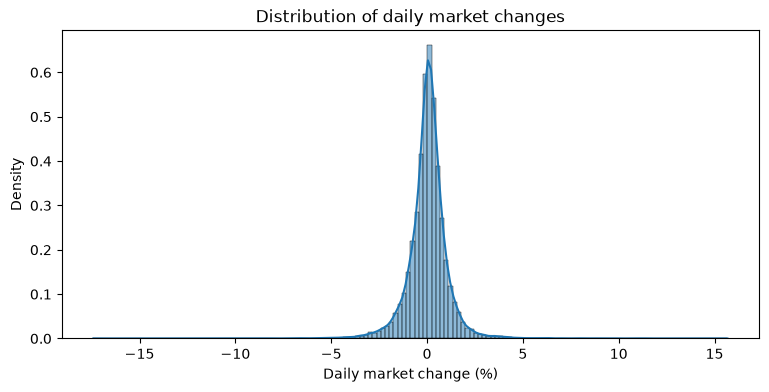

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

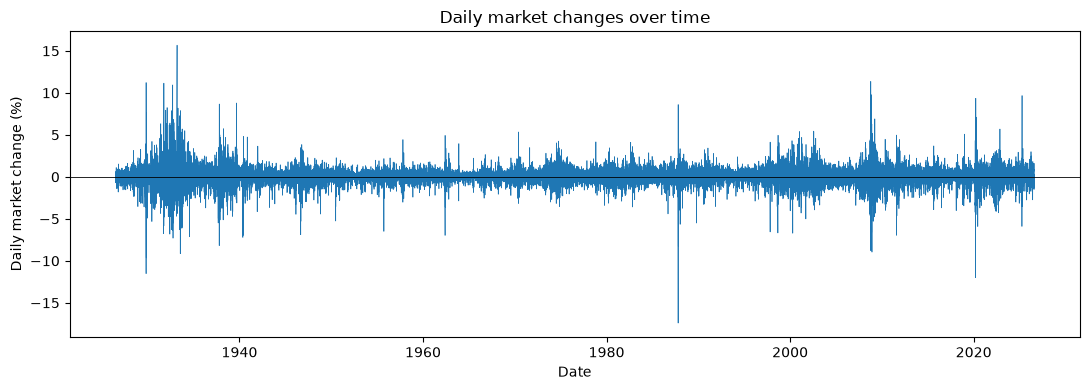

In [7]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [ ]:
# Section 2: Five-bin state model for daily market returns
labels_5 = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
bins_5 = [-np.inf, -1, -0.1, 0.1, 1, np.inf]
df['state_5'] = pd.cut(df['market_return_pct'], bins=bins_5, labels=labels_5, right=True)
df['next_state_5'] = df['state_5'].shift(-1)
df['next_return_pct'] = df['market_return_pct'].shift(-1)
pairs_5 = df.dropna(subset=['state_5', 'next_state_5', 'next_return_pct']).copy()

# 1. How many days in each category?
counts_5 = df['state_5'].value_counts().reindex(labels_5)
print('Number of days in each category:')
display(counts_5.to_frame('Days'))
print('Most common:', counts_5.idxmax(), '| Least common:', counts_5.idxmin())

# 2. Joint PMF and marginals
joint_5 = pd.crosstab(
    pairs_5['state_5'],
    pairs_5['next_state_5'],
    normalize='all'
).reindex(index=labels_5, columns=labels_5, fill_value=0)

print('Joint PMF P(today, tomorrow):')
display(joint_5)
print('Marginal P(today):')
display(joint_5.sum(axis=1).rename('Probability'))
print('Marginal P(tomorrow):')
display(joint_5.sum(axis=0).rename('Probability'))

print('Top 5 most common transitions:')
display(joint_5.stack().sort_values(ascending=False).head(5).rename('Joint probability'))

# 3. Conditional PMF P(tomorrow | today)
conditional_5 = pd.crosstab(
    pairs_5['state_5'],
    pairs_5['next_state_5'],
    normalize='index'
).reindex(index=labels_5, columns=labels_5)

print('Conditional PMF P(tomorrow | today):')
display(conditional_5)

print('Top two likely next states by current state (plus distance from uniform):')
for state, row in conditional_5.iterrows():
    top2 = row.sort_values(ascending=False).head(2)
    tvd_from_uniform = np.abs(row - 0.2).sum() / 2  # total variation distance
    print(
        f"{state}: {top2.index[0]} ({top2.iloc[0]:.1%}), "
        f"{top2.index[1]} ({top2.iloc[1]:.1%}) | TVD from uniform={tvd_from_uniform:.3f}"
    )

# 4. Conditional expectation and volatility of tomorrow's return
summary_5 = pairs_5.groupby('state_5', observed=False)['next_return_pct'].describe()
print("Tomorrow's return (%) conditional on today's category:")
display(summary_5)

print('Highest next-day standard deviation:', summary_5['std'].idxmax())
print('Largest conditional mean:', summary_5['mean'].idxmax())
print('Smallest conditional mean:', summary_5['mean'].idxmin())

Number of days in each category:


,Days
state_5,
Large loss,2759
Small loss,7452
Near zero,3441
Small gain,9785
Large gain,2859


Most common: Small gain | Least common: Large loss
Joint PMF P(today, tomorrow):


next_state_5,Large loss,Small loss,Near zero,Small gain,Large gain
state_5,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928


Marginal P(today):


state_5
Large loss    0.104925
Small loss    0.283400
Near zero     0.130861
Small gain    0.372086
Large gain    0.108728
Name: Probability, dtype: float64

... (5 outputs left out)

next_state_5,Large loss,Small loss,Near zero,Small gain,Large gain
state_5,,,,,
Large loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127317,0.234697,0.107030,0.347674,0.183281


Top two likely next states by current state (plus distance from uniform):
Large loss: Small gain (26.5%), Small loss (25.9%) | TVD from uniform=0.127
Small loss: Small gain (34.5%), Small loss (31.3%) | TVD from uniform=0.258
Near zero: Small gain (37.7%), Small loss (32.1%) | TVD from uniform=0.298
Small gain: Small gain (42.8%), Small loss (26.9%) | TVD from uniform=0.297
Large gain: Small gain (34.8%), Small loss (23.5%) | TVD from uniform=0.182
Tomorrow's return (%) conditional on today's category:


,count,mean,std,min,25%,50%,75%,max
state_5,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


Highest next-day standard deviation: Large loss
Largest conditional mean: Large gain
Smallest conditional mean: Small loss


### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

Created 21 quantile bins (requested 21).


,"(-17.411, -1.61]","(-1.61, -1.07]","(-1.07, -0.78]","(-0.78, -0.57]","(-0.57, -0.42]","(-0.42, -0.3]","(-0.3, -0.19]","(-0.19, -0.11]","(-0.11, -0.03]","(-0.03, 0.04]",...,"(0.11, 0.18]","(0.18, 0.26]","(0.26, 0.34]","(0.34, 0.44]","(0.44, 0.54]","(0.54, 0.67]","(0.67, 0.84]","(0.84, 1.09]","(1.09, 1.55]","(1.55, 15.67]"
"(-17.411, -1.61]",0.006959,0.003651,0.002928,0.001787,0.002206,0.001749,0.001825,0.001141,0.001369,0.001331,...,0.001027,0.001331,0.001331,0.001103,0.001597,0.001141,0.001940,0.002016,0.003613,0.006883
"(-1.61, -1.07]",0.004868,0.003385,0.003195,0.002206,0.002320,0.001978,0.002206,0.001673,0.001445,0.002320,...,0.001559,0.001331,0.001521,0.001711,0.001597,0.001825,0.001825,0.002890,0.002510,0.003651
"(-1.07, -0.78]",0.003651,0.003765,0.003727,0.003803,0.002244,0.001863,0.002130,0.001825,0.001483,0.002054,...,0.001978,0.002358,0.002244,0.001635,0.001369,0.002054,0.001825,0.002320,0.002510,0.002662
"(-0.78, -0.57]",0.002814,0.003689,0.003080,0.002776,0.002700,0.002472,0.002358,0.001559,0.002130,0.002396,...,0.001787,0.001940,0.001521,0.002282,0.002130,0.002282,0.001787,0.002434,0.002548,0.002092
"(-0.57, -0.42]",0.002320,0.002700,0.002890,0.002586,0.002130,0.002548,0.002624,0.002168,0.002320,0.001825,...,0.002054,0.001863,0.001749,0.002738,0.002168,0.001940,0.002662,0.001635,0.002282,0.001863


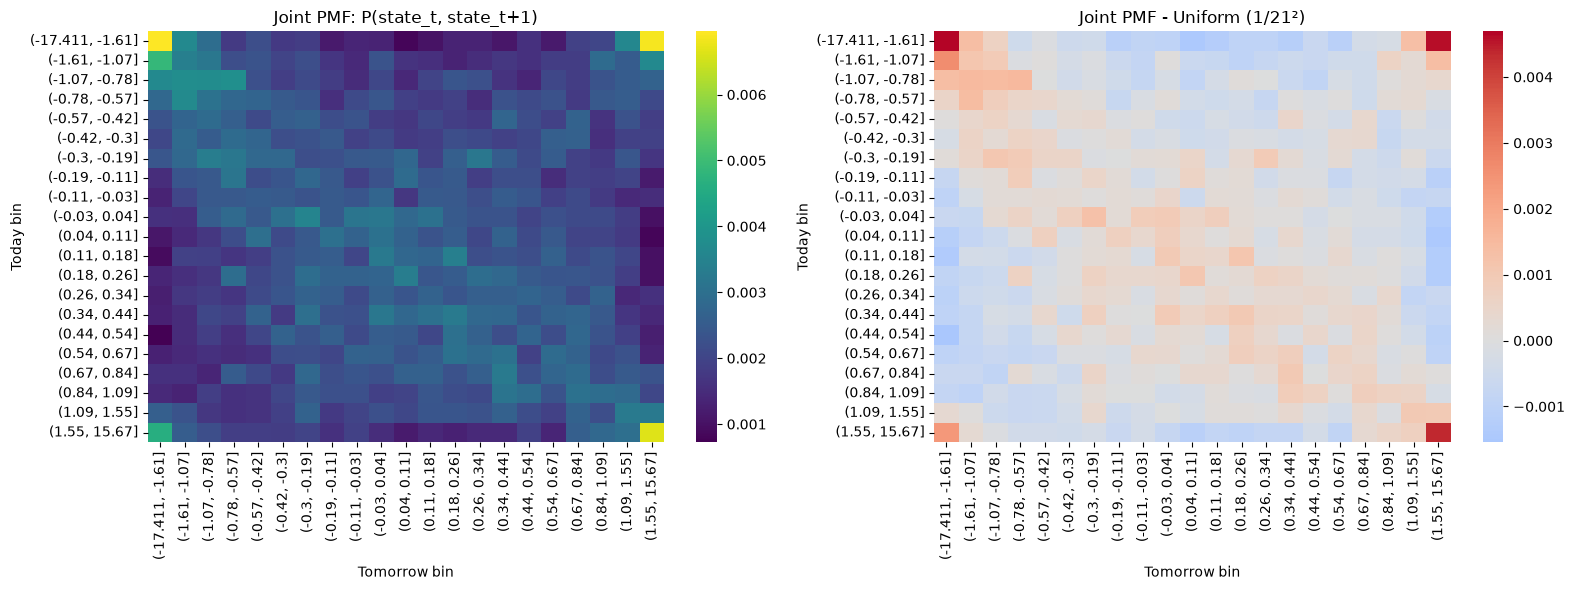

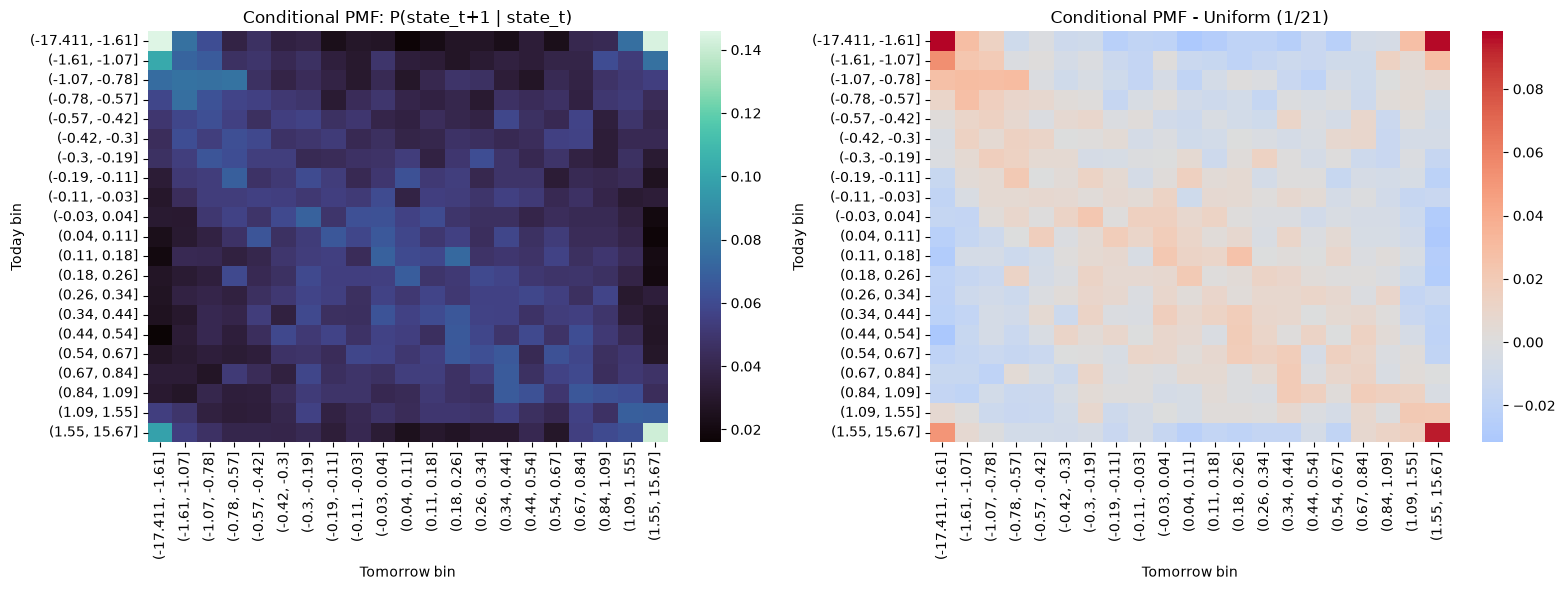

,min,mean,max,std
state_21,,,,
"(-17.411, -1.61]",-17.41,-0.013713,11.22,2.140465
"(-1.61, -1.07]",-7.36,-0.076712,6.36,1.285882
"(-1.07, -0.78]",-8.79,-0.097084,11.36,1.227976
"(-0.78, -0.57]",-8.28,-0.058594,6.16,1.049607
"(-0.57, -0.42]",-6.89,-0.024211,4.56,0.989470


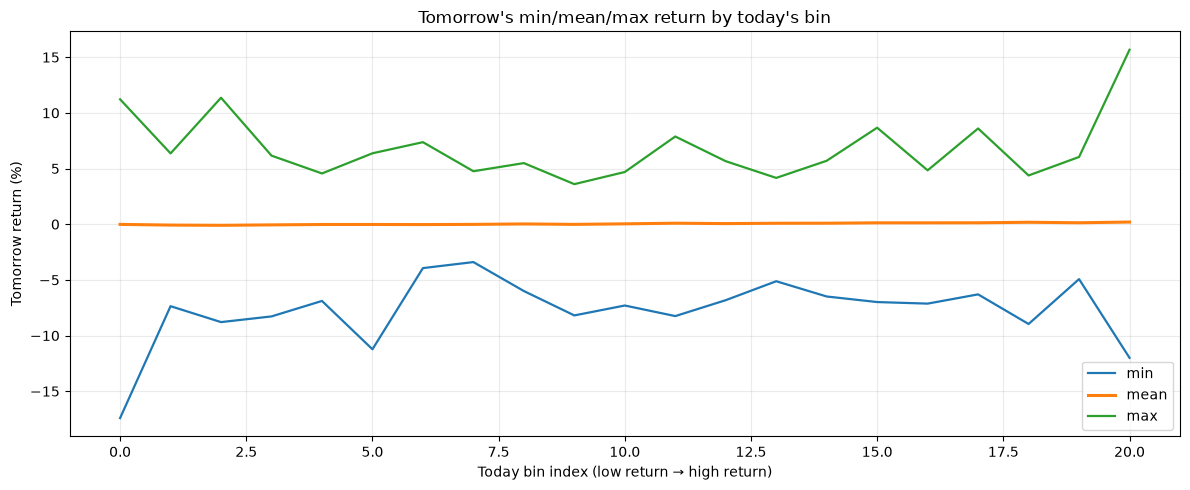

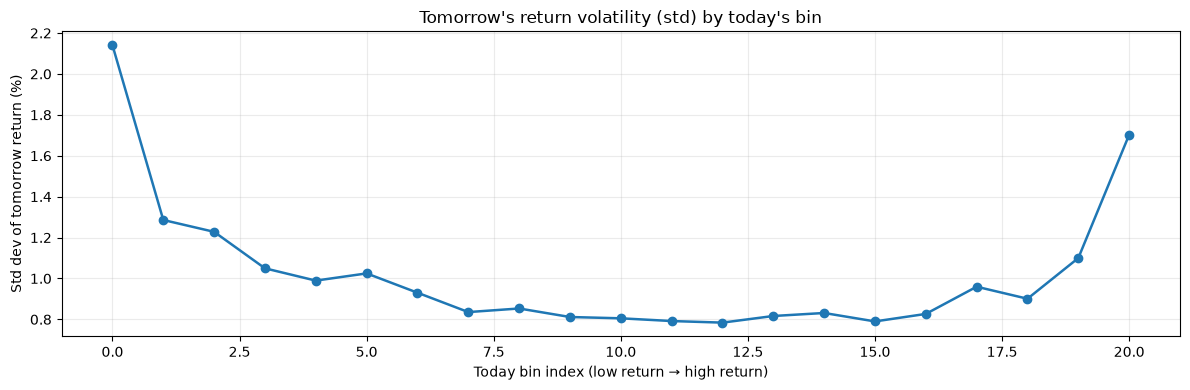

Highest expected tomorrow return bin: (1.55, 15.67]
Lowest expected tomorrow return bin: (-1.07, -0.78]
Highest volatility bin: (-17.411, -1.61]


In [10]:
# Section 3: Scaling up with quantile bins
y_t = 'state_21'
y_tp1 = 'next_state_21'

# Ensure tomorrow's return column exists for later summaries.
if 'next_return_pct' not in df.columns:
    df['next_return_pct'] = df['market_return_pct'].shift(-1)

# Build 21 quantile bins; duplicates='drop' handles tied values gracefully.
df[y_t], bin_edges = pd.qcut(
    df['market_return_pct'],
    q=21,
    retbins=True,
    duplicates='drop'
    )

df[y_tp1] = df[y_t].shift(-1)
pairs_21 = df.dropna(subset=[y_t, y_tp1]).copy()

cats_21 = df[y_t].cat.categories
k = len(cats_21)
print(f'Created {k} quantile bins (requested 21).')
if k != 21:
    print('Note: fewer bins were created because duplicate quantile cut points were dropped.')

# Joint PMF P(y_t, y_t+1)
joint_21 = pd.crosstab(pairs_21[y_t], pairs_21[y_tp1], normalize='all').reindex(
    index=cats_21,
    columns=cats_21,
    fill_value=0
    )
display(joint_21.head())

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(joint_21, cmap='viridis', ax=ax[0])
ax[0].set_title('Joint PMF: P(state_t, state_t+1)')
ax[0].set_xlabel('Tomorrow bin')
ax[0].set_ylabel('Today bin')

joint_uniform = 1 / (k**2)
sns.heatmap(joint_21 - joint_uniform, cmap='coolwarm', center=0, ax=ax[1])
ax[1].set_title(f'Joint PMF - Uniform (1/{k}²)')
ax[1].set_xlabel('Tomorrow bin')
ax[1].set_ylabel('Today bin')
plt.tight_layout()
plt.show()

# Conditional PMF P(y_t+1 | y_t)
conditional_21 = pd.crosstab(pairs_21[y_t], pairs_21[y_tp1], normalize='index').reindex(
    index=cats_21,
    columns=cats_21
    )

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(conditional_21, cmap='mako', ax=ax[0])
ax[0].set_title('Conditional PMF: P(state_t+1 | state_t)')
ax[0].set_xlabel('Tomorrow bin')
ax[0].set_ylabel('Today bin')

cond_uniform = 1 / k
sns.heatmap(conditional_21 - cond_uniform, cmap='coolwarm', center=0, ax=ax[1])
ax[1].set_title(f'Conditional PMF - Uniform (1/{k})')
ax[1].set_xlabel('Tomorrow bin')
ax[1].set_ylabel('Today bin')
plt.tight_layout()
plt.show()

# Tomorrow return summaries by today's bin
summary_21 = df.groupby(y_t, observed=False)['next_return_pct'].agg(['min', 'mean', 'max', 'std'])
display(summary_21.head())

x = np.arange(k)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(x, summary_21['min'].values, label='min', linewidth=1.6)
ax.plot(x, summary_21['mean'].values, label='mean', linewidth=2.2)
ax.plot(x, summary_21['max'].values, label='max', linewidth=1.6)
ax.set_title("Tomorrow's min/mean/max return by today's bin")
ax.set_xlabel('Today bin index (low return → high return)')
ax.set_ylabel("Tomorrow return (%)")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(x, summary_21['std'].values, marker='o', linewidth=1.8)
ax.set_title("Tomorrow's return volatility (std) by today's bin")
ax.set_xlabel('Today bin index (low return → high return)')
ax.set_ylabel('Std dev of tomorrow return (%)')
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print('Highest expected tomorrow return bin:', summary_21['mean'].idxmax())
print('Lowest expected tomorrow return bin:', summary_21['mean'].idxmin())
print('Highest volatility bin:', summary_21['std'].idxmax())